In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import GKSIAS

# Toy problem

In [23]:
n = 1000 
np.random.seed(0)
p = 0.01
ground_truth = np.random.binomial(1, p, size=n).astype(np.float64)

noise_stdev = 0.01
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=5, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

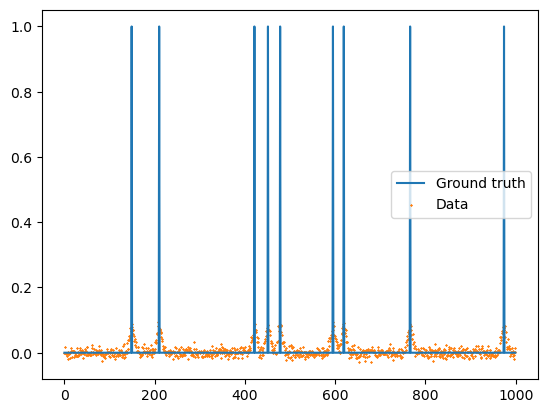

In [25]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [28]:
#Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
#L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
L = jlinops.IdentityOperator((n,n))

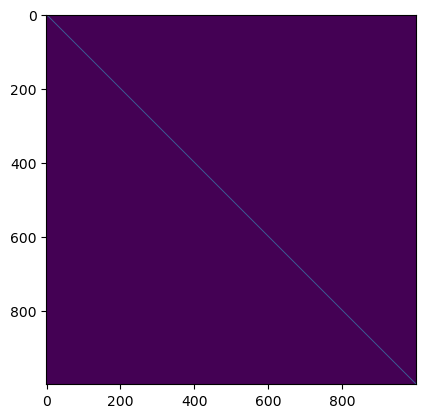

In [30]:
plt.imshow( jlinops.black_box_to_dense(L) )
plt.show()

# Use solver

In [47]:
gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)
data = gksias_solver.solve(n_iter=50, hyperpr_r=1, hyperpr_beta=1.5 + 1e-3, x_true=ground_truth, regparam="gcv", plotting=True, pdf_name="mgcv_1d_deblurring_gksias.pdf", gcv_gamma=0.8, helping=True)
#data = gksias_solver.solve(n_iter=50, hyperpr_r=-1.0, hyperpr_beta=1.0, x_true=ground_truth, regparam="gcv", plotting=True, pdf_name="mgcv_1d_deblurring_sparse_signal_gksias.pdf", gcv_gamma=0.1, helping=True)

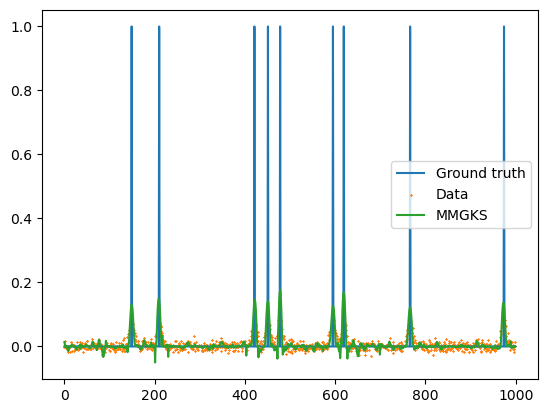

In [48]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()

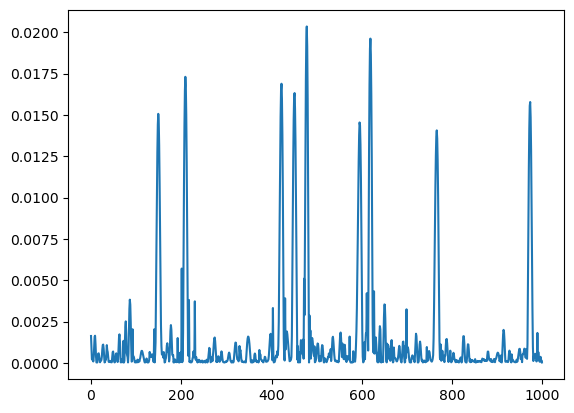

In [49]:
plt.plot(data["theta"])
plt.show()

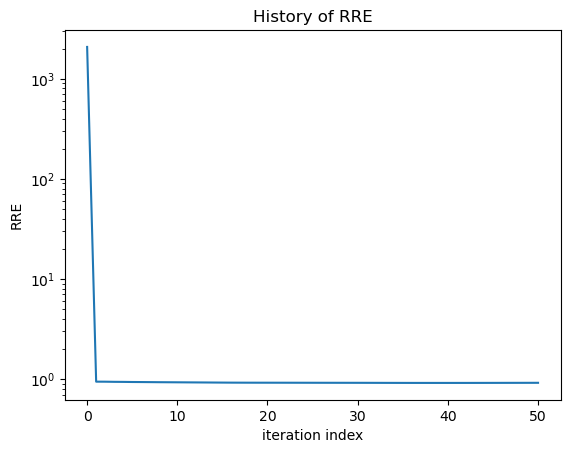

In [50]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

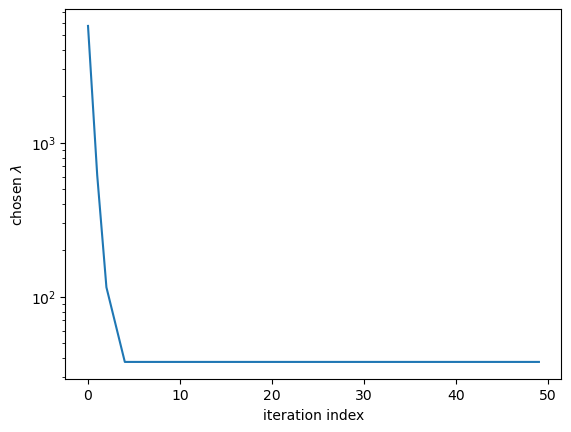

In [51]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

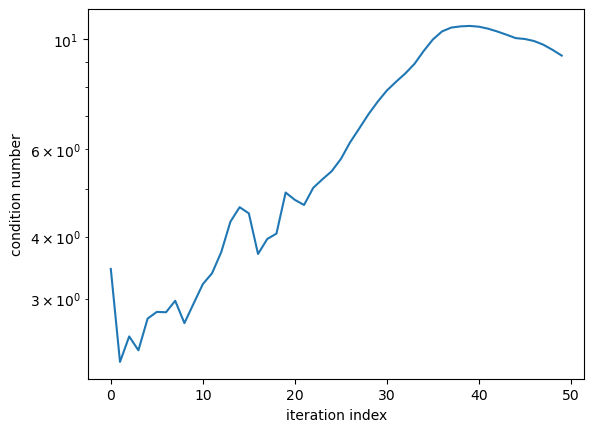

In [52]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("condition number")
plt.show()

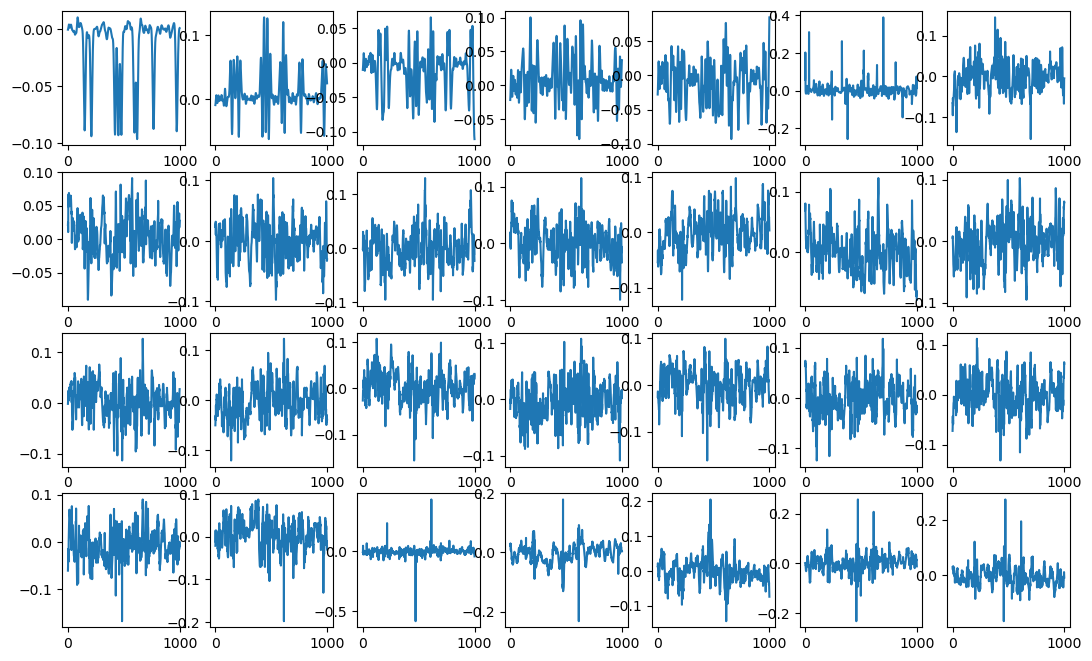

In [53]:
fig, axs = plt.subplots(4,7,figsize=(13,8))

for j, ax in enumerate(axs.reshape(-1)):
    ax.plot(data["V"][:,j])